# 各股票回测：训练、测试与全时段
对每只股票分别比较 Buy and Hold、SMA 和 MACD；真实 Agent CSV 接入后使用相同回测入口。每种策略只允许仓位 1（持有）和 0（空仓）。

流程：完整行情 → 训练／测试切分 → 信号保存 CSV → 读取并映射仓位 → 分范围计算收益 → 指标、净值图及结果导出。选择 py311_env 后从头运行。

In [1]:
from pathlib import Path
import sys
import json

ROOT = Path.cwd().resolve()
if not (ROOT / "config.json").exists():
    ROOT = ROOT / "tradingagents_quant_backtest"
if not (ROOT / "config.json").exists():
    raise FileNotFoundError("请从项目目录打开 analysis.ipynb")
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from data import (DATA_DIR, data_hash, read_sources, read_prices, validate_prices, schedule,
                  total_return_index, digest, json_bytes, utcnow)
from signals import load_decisions, validate_decisions, decision_sessions
from settings import load_config, code_hash

## 参数
默认评价配置中的全部股票，不需要选择某一个时间段。日期、指标窗口和费率集中在 config.json。
RETURN_TYPE 控制资产收益输入，NAV_MODE 控制加法或复利净值。AGENT_CSV 留空时只评价规则策略。

In [2]:
cfg = load_config()
TICKERS = cfg["tickers"]  # 可改为子集，例如 ["AAPL"]
AGENT_CSV = None  # 完整期间的真实决策文件，例如 ROOT / "data/decisions/agent.csv"
AGENT_NAME = "TradingAgents"
RETURN_TYPE = "simple"  # simple / log
NAV_MODE = "additive"   # additive / compound

train_start, train_end = cfg["splits"]["train"]
test_start, test_end = cfg["splits"]["test"]
periods = {"train": (train_start, train_end),
           "test": (test_start, test_end),
           "train_test": (train_start, test_end)}
period_names = {"train": "Train", "test": "Test", "train_test": "Train + Test"}
pd.DataFrame(periods, index=["start", "end"]).T

,start,end
train,2024-01-01,2026-05-31
test,2026-06-01,2026-10-09
train_test,2024-01-01,2026-10-09


In [3]:
if not TICKERS or len(set(TICKERS)) != len(TICKERS) or not set(TICKERS).issubset(cfg["tickers"]):
    raise ValueError("TICKERS 必须是配置股票的非空子集")
if RETURN_TYPE not in ["simple", "log"] or NAV_MODE not in ["additive", "compound"]:
    raise ValueError("收益类型为 simple/log，净值口径为 additive/compound")
sources = read_sources()

## 加载完整行情并计算未来一期收益
所有股票统一加载到测试结束日，保留预热行情。指标仅依赖各信号日已经发生的历史数据。

DateTime 为本期开盘，return_end 为下一交易日开盘。收盘后信号在下一开盘生效。资产收益 `(next_open + next_dividend) * next_split / open - 1` 包含拆股分红；末行未知收益不补零。

In [4]:
price_histories = {ticker: read_prices(ticker, cfg, test_end) for ticker in TICKERS}
market_tables = {}
for ticker, prices in price_histories.items():
    df = prices.copy()
    sessions = schedule(cfg["warmup_start"], test_end)
    df.index = pd.DatetimeIndex(sessions.open.dt.tz_convert(cfg["timezone"]), name="DateTime")
    df["return_end"] = pd.Series(df.index, index=df.index).shift(-1)
    df["technical_index"] = total_return_index(df)
    df["simple_ret"] = df.technical_index.pct_change()
    df["log_ret"] = np.log(df.technical_index / df.technical_index.shift(1))
    df["asset_ret"] = (df.open.shift(-1) + df.dividend.shift(-1)) * df.split.shift(-1) / df.open - 1
    df["pct"] = df.asset_ret if RETURN_TYPE == "simple" else np.log1p(df.asset_ret)
    market_tables[ticker] = df
pd.concat({ticker: df[["open", "close", "pct", "return_end"]].tail(3)
           for ticker, df in market_tables.items()}, names=["ticker"])

open       close       pct  \
ticker DateTime                                                      
AAPL   2026-10-07 09:30:00-04:00  336.959991  336.670013 -0.000415   
       2026-10-08 09:30:00-04:00  336.820007  340.420013 -0.015201   
       2026-10-09 09:30:00-04:00  331.700012  336.640015       NaN   
GOOGL  2026-10-07 09:30:00-04:00  346.720001  350.500000  0.018516   
       2026-10-08 09:30:00-04:00  353.140015  348.290009 -0.004927   
       2026-10-09 09:30:00-04:00  351.399994  351.660004       NaN   
AMZN   2026-10-07 09:30:00-04:00  254.229996  259.920013  0.021673   
       2026-10-08 09:30:00-04:00  259.739990  254.059998 -0.012474   
       2026-10-09 09:30:00-04:00  256.500000  262.429993       NaN   

                                                return_end  
ticker DateTime                                             
AAPL   2026-10-07 09:30:00-04:00 2026-10-08 09:30:00-04:00  
       2026-10-08 09:30:00-04:00 2026-10-09 09:30:00-04:00  
       2026-10-09 09:30:00-04:00                       NaT  
GOOGL  2026-10-07 09:30:00-04:00 2026-10-08 09:30:00-04:00  
       2026-10-08 09:30:00-04:00 2026-10-09 09:30:00-04:00  
       2026-10-09 09:30:00-04:00                       NaT  
AMZN   2026-10-07 09:30:00-04:00 2026-10-08 09:30:00-04:00  
       2026-10-08 09:30:00-04:00 2026-10-09 09:30:00-04:00  
       2026-10-09 09:30:00-04:00                       NaT

## 训练与测试切分
原验证期并入测试期。训练与测试各自只计入收益终点位于本段的区间，训练收益不跨入测试期。
全时段保留训练到测试之间的真实持有收益，因此不能简单把两个独立回测结果相加。
这里同时列出全部股票、全部范围的实际数据量，避免测试数据没有加载却继续运行。

In [5]:
def select_period(frame, start, end):
    session_date = pd.to_datetime(frame.date)
    return_date = frame.return_end.dt.tz_localize(None).dt.normalize()
    mask = session_date.between(start, end) & return_date.le(pd.Timestamp(end))
    selected = frame.loc[mask].dropna(subset=["pct", "return_end"]).copy()
    if selected.empty:
        raise ValueError(f"{start} 至 {end} 没有可回测收益区间")
    return selected

In [6]:
data_splits = {
    (ticker, period): select_period(df, start, end)
    for ticker, df in market_tables.items()
    for period, (start, end) in periods.items()
}
split_summary = pd.DataFrame([
    {"ticker": ticker, "period": period, "start": frame.date.iloc[0],
     "last_return_end": frame.return_end.iloc[-1], "return_intervals": len(frame)}
    for (ticker, period), frame in data_splits.items()
])
split_summary

,ticker,period,start,last_return_end,return_intervals
0,AAPL,train,2024-01-02,2026-05-29 09:30:00-04:00,603
1,AAPL,test,2026-06-01,2026-10-09 09:30:00-04:00,91
2,AAPL,train_test,2024-01-02,2026-10-09 09:30:00-04:00,695
3,GOOGL,train,2024-01-02,2026-05-29 09:30:00-04:00,603
4,GOOGL,test,2026-06-01,2026-10-09 09:30:00-04:00,91
5,GOOGL,train_test,2024-01-02,2026-10-09 09:30:00-04:00,695
6,AMZN,train,2024-01-02,2026-05-29 09:30:00-04:00,603
7,AMZN,test,2026-06-01,2026-10-09 09:30:00-04:00,91
8,AMZN,train_test,2024-01-02,2026-10-09 09:30:00-04:00,695


## 生成规则信号并保存 CSV
三种规则在完整期间一次生成。Buy and Hold 首次 BUY、之后 HOLD；SMA 均线差和 MACD 柱值为正时 BUY、负时 SELL、零时 HOLD。
各股票单独保存 CSV。信号覆盖训练前最后交易日到测试末日，后续回测只读取落盘文件。

In [7]:
def calculate_indicators(prices, cfg, end):
    p = prices.loc[prices.date <= end].copy().set_index("date", drop=False)
    p["technical_index"] = total_return_index(p)
    tr = p.technical_index
    fast, slow = cfg["sma"]["fast"], cfg["sma"]["slow"]
    p["sma_fast"] = tr.rolling(fast, min_periods=fast).mean()
    p["sma_slow"] = tr.rolling(slow, min_periods=slow).mean()
    p["sma_score"] = p.sma_fast - p.sma_slow
    fast, slow, signal = (cfg["macd"][k] for k in ["fast", "slow", "signal"])
    p["macd"] = (tr.ewm(span=fast, adjust=False, min_periods=fast).mean()
                 - tr.ewm(span=slow, adjust=False, min_periods=slow).mean())
    p["macd_signal"] = p.macd.ewm(span=signal, adjust=False, min_periods=signal).mean()
    p["macd_score"] = p.macd - p.macd_signal
    return p


def baseline_signals(indicators, ticker, strategy, start, end, cfg):
    sessions = decision_sessions(start, end)
    days = sessions.index.strftime("%Y-%m-%d")
    if strategy == "buy_hold":
        actions = np.full(len(days), "HOLD", dtype=object)
        actions[0] = "BUY"
    elif strategy in ["sma", "macd"]:
        score = indicators.reindex(days)[f"{strategy}_score"]
        if not np.isfinite(score.to_numpy()).all():
            raise ValueError("指标预热不足或缺少信号日行情")
        actions = np.select([score > 0, score < 0], ["BUY", "SELL"], default="HOLD")
    else:
        raise ValueError("未知基线")
    frame = pd.DataFrame({
        "ticker": ticker,
        "decision_time": [pd.Timestamp(day + " " + cfg["decision_clock"], tz=cfg["timezone"]).isoformat() for day in days],
        "information_cutoff": [close.isoformat() for close in sessions.close],
        "action": actions, "strategy_version": f"{strategy}-v1",
        "source": "baseline",
    })
    return validate_decisions(frame, ticker, start, end, source="baseline")


def signals(prices, ticker, strategy, start, end, cfg):
    # 供规则切换和关键测试复用；公式就在上面的单元格中。
    indicators = calculate_indicators(prices, cfg, end)
    return baseline_signals(indicators, ticker, strategy, start, end, cfg)

In [8]:
baseline_tables = {}
for ticker, prices in price_histories.items():
    indicators = calculate_indicators(prices, cfg, test_end)
    baseline_tables[ticker] = {
        strategy: baseline_signals(indicators, ticker, strategy, train_start, test_end, cfg)
        for strategy in ["buy_hold", "sma", "macd"]
    }


In [9]:
baseline_paths = {}
for ticker, tables in baseline_tables.items():
    path = ROOT / "data/decisions" / f"baseline_{ticker}_train_test.csv"
    path.parent.mkdir(parents=True, exist_ok=True)
    exported = pd.concat([rows.assign(strategy=strategy) for strategy, rows in tables.items()], ignore_index=True)
    sessions = decision_sessions(train_start, test_end)
    execution_dates = dict(zip(sessions.index.strftime("%Y-%m-%d"),
                              [*sessions.open.iloc[1:].dt.tz_convert(cfg["timezone"]), pd.NaT]))
    exported["DateTime"] = exported.session.map(execution_dates)
    exported.to_csv(path, index=False)
    baseline_paths[ticker] = path
pd.Series(baseline_paths, name="signals_csv")

AAPL     /Users/Admin/Documents/hkust/course/BDT5018NLP...
GOOGL    /Users/Admin/Documents/hkust/course/BDT5018NLP...
AMZN     /Users/Admin/Documents/hkust/course/BDT5018NLP...
Name: signals_csv, dtype: object

## 读取策略 CSV 与 Agent 接口
统一接口为 decision_tables[(股票, 策略ID)] 和 strategy_names[策略ID]。新增策略先保存 CSV，再校验并加入这两个字典，共用后面的收益计算。

Agent CSV 必须覆盖当前评价股票的完整期间，source 为 portfolio_manager，BUY／SELL／HOLD 保留文字。没有真实 CSV 时不生成 Agent 结果。手动修改基线 CSV 后，从本节继续运行以免覆盖。

In [10]:
decision_tables = {}
for ticker, path in baseline_paths.items():
    baseline_input = load_decisions(path)
    if set(baseline_input.ticker) != {ticker} or set(baseline_input.strategy) != {"buy_hold", "sma", "macd"}:
        raise ValueError("Missing/extra baseline stocks or strategies in CSV")
    for strategy, rows in baseline_input.groupby("strategy", sort=False):
        decision_tables[ticker, strategy] = validate_decisions(
            rows, ticker, train_start, test_end, source="baseline")

In [11]:
strategy_names = {
    "buy_hold": "Buy and Hold",
    "sma": f"SMA Trend ({cfg['sma']['fast']}/{cfg['sma']['slow']})",
    "macd": f"MACD Trend ({cfg['macd']['fast']}/{cfg['macd']['slow']}/{cfg['macd']['signal']})",
}
if AGENT_CSV is not None:
    imported = load_decisions(AGENT_CSV)
    if not set(imported.ticker).issubset(cfg["tickers"]):
        raise ValueError("Agent CSV 含未知股票")
    for ticker in TICKERS:
        rows = imported.loc[imported.ticker == ticker]
        decision_tables[ticker, "agent"] = validate_decisions(rows, ticker, train_start, test_end)
    strategy_names["agent"] = AGENT_NAME
pd.DataFrame([{"ticker": ticker, "strategy": strategy, "strategy_name": strategy_names[strategy],
               "decision_rows": len(rows)} for (ticker, strategy), rows in decision_tables.items()])

,ticker,strategy,strategy_name,decision_rows
0,AAPL,buy_hold,Buy and Hold,697
1,AAPL,sma,SMA Trend (20/50),697
2,AAPL,macd,MACD Trend (12/26/9),697
3,GOOGL,buy_hold,Buy and Hold,697
4,GOOGL,sma,SMA Trend (20/50),697
5,GOOGL,macd,MACD Trend (12/26/9),697
6,AMZN,buy_hold,Buy and Hold,697
7,AMZN,sma,SMA Trend (20/50),697
8,AMZN,macd,MACD Trend (12/26/9),697


## 只做多仓位映射
BUY → 1，SELL → 0，HOLD → 延续此前仓位。HOLD 起始时为空仓，缺失决策直接报错。
不再保存负数动作编码；signal 和 position 均为 0/1。成交时间由交易日历映射，CSV 的额外列不覆盖计算字段。

In [12]:
def prepare_backtest(prices, decisions, return_type="simple"):
    if prices.empty:
        raise ValueError("Empty backtest prices")
    p = validate_prices(prices, str(prices.date.iloc[0]), str(prices.date.iloc[-1]))
    d = decisions.copy().reset_index(drop=True)
    expected = decision_sessions(p.date.iloc[0], p.date.iloc[-1]).index.strftime("%Y-%m-%d").tolist()
    if d.session.tolist() != expected or not d.action.isin(["BUY", "SELL", "HOLD"]).all():
        raise ValueError("Missing/duplicate/unsorted/invalid decisions")
    # 只选明确的信号字段，额外 close/cash 等列不进入计算。
    columns = ["session", "action", "decision_time", "information_cutoff", "strategy_version", "source"]
    d = d.filter(items=columns)
    d["target_position"] = d.action.map({"BUY": 1., "SELL": 0., "HOLD": np.nan}).ffill().fillna(0.)
    d["signal"] = d.target_position
    d["date"] = d.session.shift(-1)
    executed = d.iloc[:-1].rename(columns={"session": "signal_session"})
    frame = p.merge(executed, on="date", how="left", validate="one_to_one")
    sessions = schedule(p.date.iloc[0], p.date.iloc[-1])
    frame.index = pd.DatetimeIndex(sessions.open.dt.tz_convert("America/New_York"), name="DateTime")
    frame["return_end"] = pd.Series(frame.index, index=frame.index).shift(-1)
    frame["asset_ret"] = ((frame.open.shift(-1) + frame.dividend.shift(-1)) * frame.split.shift(-1) / frame.open - 1)
    if return_type not in ["simple", "log"]:
        raise ValueError("未知收益率类型")
    frame["pct"] = frame.asset_ret if return_type == "simple" else np.log1p(frame.asset_ret)
    frame["position"] = frame.target_position
    return frame.dropna(subset=["pct", "return_end"]).copy()

In [13]:
position_tables = {}
for (ticker, strategy), decisions in decision_tables.items():
    prices = price_histories[ticker]
    prices = prices.loc[prices.date.between(train_start, test_end)]
    full_frame = prepare_backtest(prices, decisions, return_type=RETURN_TYPE)
    for period, (start, end) in periods.items():
        position_tables[ticker, period, strategy] = select_period(full_frame, start, end)
pd.concat({key: frame[["open", "action", "signal", "position", "pct"]].head(3)
           for key, frame in position_tables.items()}, names=["ticker", "period", "strategy"])

open action  \
ticker period     strategy DateTime                                       
AAPL   train      buy_hold 2024-01-02 09:30:00-05:00  187.149994    BUY   
                           2024-01-03 09:30:00-05:00  184.220001   HOLD   
                           2024-01-04 09:30:00-05:00  182.149994   HOLD   
       test       buy_hold 2026-06-01 09:30:00-04:00  309.630005   HOLD   
                           2026-06-02 09:30:00-04:00  307.459991   HOLD   
...                                                          ...    ...   
AMZN   test       macd     2026-06-02 09:30:00-04:00  257.160004   SELL   
                           2026-06-03 09:30:00-04:00  254.699997   SELL   
       train_test macd     2024-01-02 09:30:00-05:00  151.539993   SELL   
                           2024-01-03 09:30:00-05:00  149.199997   SELL   
                           2024-01-04 09:30:00-05:00  145.589996   SELL   

                                                      signal  position  \
ticker period     strategy DateTime                                      
AAPL   train      buy_hold 2024-01-02 09:30:00-05:00     1.0       1.0   
                           2024-01-03 09:30:00-05:00     1.0       1.0   
                           2024-01-04 09:30:00-05:00     1.0       1.0   
       test       buy_hold 2026-06-01 09:30:00-04:00     1.0       1.0   
                           2026-06-02 09:30:00-04:00     1.0       1.0   
...                                                      ...       ...   
AMZN   test       macd     2026-06-02 09:30:00-04:00     0.0       0.0   
                           2026-06-03 09:30:00-04:00     0.0       0.0   
       train_test macd     2024-01-02 09:30:00-05:00     0.0       0.0   
                           2024-01-03 09:30:00-05:00     0.0       0.0   
                           2024-01-04 09:30:00-05:00     0.0       0.0   

                                                           pct  
ticker period     strategy DateTime                             
AAPL   train      buy_hold 2024-01-02 09:30:00-05:00 -0.015656  
                           2024-01-03 09:30:00-05:00 -0.011237  
                           2024-01-04 09:30:00-05:00 -0.000878  
       test       buy_hold 2026-06-01 09:30:00-04:00 -0.007008  
                           2026-06-02 09:30:00-04:00  0.021857  
...                                                        ...  
AMZN   test       macd     2026-06-02 09:30:00-04:00 -0.009566  
                           2026-06-03 09:30:00-04:00 -0.006203  
       train_test macd     2024-01-02 09:30:00-05:00 -0.015441  
                           2024-01-03 09:30:00-05:00 -0.024196  
                           2024-01-04 09:30:00-05:00 -0.006182  

[81 rows x 5 columns]

## 仓位收益、费用与净值
`strategy_ret = position * asset_ret - abs(position_changes) * fee`。
默认加法净值 `1 + cumsum(strategy_ret)`，可选复利 `cumprod(1 + strategy_ret)`。

纯训练、纯测试分别从净值 1 和空仓开始，第一期按当时已知决策形成仓位并扣建仓费；HOLD 所延续的目标仓位由此前决策确定。
训练＋测试从训练起点连续计算，在边界不重复扣建仓费。不强制期末清仓。
仓位变化可以为 −1，表示卖出，不表示负仓位。

In [14]:
def cal_net_values(post, ret, fee=0.0005, return_type="simple",
                   nav_mode="additive", initial_position=0.):
    post = np.asarray(post, dtype=float)
    ret = np.asarray(ret, dtype=float)
    assert post.ndim == ret.ndim == 1 and len(post) == len(ret) > 0
    assert np.isfinite(post).all() and np.isfinite(ret).all()
    assert np.isin(post, [0., 1.]).all() and initial_position in [0., 1.], "只允许 0/1 仓位"
    assert np.isfinite(fee) and fee >= 0 and np.isfinite(initial_position)
    if return_type == "log":
        asset_ret = np.expm1(ret)
    elif return_type == "simple":
        asset_ret = ret
    else:
        raise ValueError("未知收益率类型")
    position_changes = np.diff(np.r_[initial_position, post])
    ret_array = post * asset_ret - np.abs(position_changes) * fee
    if nav_mode == "additive":
        net_values = 1 + ret_array.cumsum()
    elif nav_mode == "compound":
        assert (ret_array > -1).all(), "非正净值需另行处理"
        net_values = (1 + ret_array).cumprod()
    else:
        raise ValueError("未知净值口径")
    return net_values, ret_array

def calculate_mdd(net_values):
    values = np.asarray(net_values, dtype=float)
    assert values.ndim == 1 and len(values) > 0 and np.isfinite(values).all() and (values > 0).all()
    nav = np.r_[1., values]
    drawdown = nav / np.maximum.accumulate(nav) - 1
    index = int(drawdown.argmin())
    return float(drawdown[index]), max(0, index - 1)


def calculate_sharpe(daily_ret, rf=0., periods=252):
    excess = np.asarray(daily_ret, dtype=float) - rf / periods
    assert excess.ndim == 1 and len(excess) > 0 and np.isfinite(excess).all()
    std = excess.std(ddof=0)
    return float(excess.mean() / std * np.sqrt(periods)) if len(excess) > 1 and std > 1e-14 else np.nan

In [15]:
def run_backtest(frame, fee, return_type="simple", nav_mode="additive"):
    df = frame.copy()
    df["position_changes"] = np.diff(np.r_[0., df.position.to_numpy()])
    df["turnover"] = df.position_changes.abs()
    df["cost"] = df.turnover * fee
    df["net_values"], df["strategy_ret"] = cal_net_values(
        df.position, df.pct, fee=fee, return_type=return_type, nav_mode=nav_mode)
    df["running_peak"] = df.net_values.cummax().clip(lower=1.)
    df["drawdown"] = df.net_values / df.running_peak - 1
    return df

## 全部股票与范围的策略指标
收益归属于 return_end 的交易日。日收益在加法模式求和、复利模式复合；夏普使用 ddof=0。百分比回撤包含初始净值 1。
训练＋测试用于观察连续表现，不能替代纯测试的样本外评价。

In [16]:
def evaluate_backtest(df, nav_mode="additive", annualization=252, risk_free_rate=0.):
    dates = df.return_end.dt.normalize()
    if nav_mode == "compound":
        daily_ret = (1 + df.strategy_ret).groupby(dates).prod() - 1
    else:
        daily_ret = df.strategy_ret.groupby(dates).sum()
    max_drawdown, _ = calculate_mdd(df.net_values)
    return pd.Series({
        "cumulative_return": df.net_values.iloc[-1] - 1,
        "max_drawdown": max_drawdown,
        "sharpe": calculate_sharpe(daily_ret, rf=risk_free_rate, periods=annualization),
        "annualized_volatility": daily_ret.std(ddof=0) * np.sqrt(annualization) if len(daily_ret) > 1 else np.nan,
        "position_change_count": int(df.turnover.gt(0).sum()),
        "turnover_sum": df.turnover.sum(), "cost_sum": df.cost.sum(),
        "return_intervals": len(df), "return_days": len(daily_ret),
    })

In [17]:
fee = (cfg["commission_bps"] + cfg["slippage_bps"]) / 10000
backtests = {key: run_backtest(frame, fee, return_type=RETURN_TYPE, nav_mode=NAV_MODE)
             for key, frame in position_tables.items()}
metrics_table = pd.DataFrame([
    {"ticker": ticker, "period": period, "strategy": strategy,
     "strategy_name": strategy_names[strategy],
     **evaluate_backtest(frame, nav_mode=NAV_MODE, annualization=cfg["annualization"],
                         risk_free_rate=cfg["risk_free_rate"]).to_dict()}
    for (ticker, period, strategy), frame in backtests.items()
]).set_index(["ticker", "period", "strategy"])
metrics_table

strategy_name  cumulative_return  \
ticker period     strategy                                            
AAPL   train      buy_hold          Buy and Hold           0.619931   
       test       buy_hold          Buy and Hold           0.086252   
       train_test buy_hold          Buy and Hold           0.700288   
       train      sma          SMA Trend (20/50)           0.326561   
       test       sma          SMA Trend (20/50)          -0.002071   
       train_test sma          SMA Trend (20/50)           0.318595   
       train      macd      MACD Trend (12/26/9)           0.133203   
       test       macd      MACD Trend (12/26/9)           0.086225   
       train_test macd      MACD Trend (12/26/9)           0.213533   
GOOGL  train      buy_hold          Buy and Hold           1.160329   
       test       buy_hold          Buy and Hold          -0.045386   
       train_test buy_hold          Buy and Hold           1.093307   
       train      sma          SMA Trend (20/50)           0.950632   
       test       sma          SMA Trend (20/50)          -0.089779   
       train_test sma          SMA Trend (20/50)           0.839218   
       train      macd      MACD Trend (12/26/9)           0.602257   
       test       macd      MACD Trend (12/26/9)          -0.084748   
       train_test macd      MACD Trend (12/26/9)           0.517508   
AMZN   train      buy_hold          Buy and Hold           0.719488   
       test       buy_hold          Buy and Hold          -0.016402   
       train_test buy_hold          Buy and Hold           0.685655   
       train      sma          SMA Trend (20/50)           0.219644   
       test       sma          SMA Trend (20/50)          -0.189681   
       train_test sma          SMA Trend (20/50)           0.012533   
       train      macd      MACD Trend (12/26/9)           0.185830   
       test       macd      MACD Trend (12/26/9)          -0.082913   
       train_test macd      MACD Trend (12/26/9)           0.102918   

                            max_drawdown    sharpe  annualized_volatility  \
ticker period     strategy                                                  
AAPL   train      buy_hold     -0.280875  0.897317               0.288722   
       test       buy_hold     -0.128732  0.770666               0.309931   
       train_test buy_hold     -0.280875  0.871340               0.291410   
       train      sma          -0.211100  0.738323               0.184842   
       test       sma          -0.128732 -0.019971               0.287132   
       train_test sma          -0.211100  0.574291               0.201151   
       train      macd         -0.254395  0.312365               0.178212   
       test       macd         -0.094654  1.012135               0.235915   
       train_test macd         -0.254395  0.414618               0.186738   
GOOGL  train      buy_hold     -0.245133  1.464210               0.331178   
       test       buy_hold     -0.155468 -0.350874               0.358204   
       train_test buy_hold     -0.245133  1.182845               0.335143   
       train      sma          -0.161953  1.404038               0.282955   
       test       sma          -0.097672 -1.851974               0.134245   
       train_test sma          -0.161953  1.132465               0.268699   
       train      macd         -0.135968  1.065649               0.236184   
       test       macd         -0.138063 -0.984483               0.238386   
       train_test macd         -0.135968  0.793317               0.236530   
AMZN   train      buy_hold     -0.249450  0.885145               0.339697   
       test       buy_hold     -0.156774 -0.127856               0.355257   
       train_test buy_hold     -0.249450  0.727416               0.341773   
       train      sma          -0.210686  0.364238               0.252009   
       test       sma          -0.208477 -3.177190               0.165325   
       train_test sma          -0.282904  0.018716

### 纯训练结果


In [18]:
train_metrics = metrics_table.xs("train", level="period")
train_metrics


strategy_name  cumulative_return  max_drawdown  \
ticker strategy                                                          
AAPL   buy_hold          Buy and Hold           0.619931     -0.280875   
       sma          SMA Trend (20/50)           0.326561     -0.211100   
       macd      MACD Trend (12/26/9)           0.133203     -0.254395   
GOOGL  buy_hold          Buy and Hold           1.160329     -0.245133   
       sma          SMA Trend (20/50)           0.950632     -0.161953   
       macd      MACD Trend (12/26/9)           0.602257     -0.135968   
AMZN   buy_hold          Buy and Hold           0.719488     -0.249450   
       sma          SMA Trend (20/50)           0.219644     -0.210686   
       macd      MACD Trend (12/26/9)           0.185830     -0.252522   

                   sharpe  annualized_volatility  position_change_count  \
ticker strategy                                                           
AAPL   buy_hold  0.897317               0.288722                    1.0   
       sma       0.738323               0.184842                   17.0   
       macd      0.312365               0.178212                   49.0   
GOOGL  buy_hold  1.464210               0.331178                    1.0   
       sma       1.404038               0.282955                    9.0   
       macd      1.065649               0.236184                   52.0   
AMZN   buy_hold  0.885145               0.339697                    1.0   
       sma       0.364238               0.252009                   13.0   
       macd      0.345380               0.224855                   60.0   

                 turnover_sum  cost_sum  return_intervals  return_days  
ticker strategy                                                         
AAPL   buy_hold           1.0     0.001             603.0        603.0  
       sma               17.0     0.017             603.0        603.0  
       macd              49.0     0.049             603.0        603.0  
GOOGL  buy_hold           1.0     0.001             603.0        603.0  
       sma                9.0     0.009             603.0        603.0  
       macd              52.0     0.052             603.0        603.0  
AMZN   buy_hold           1.0     0.001             603.0        603.0  
       sma               13.0     0.013             603.0        603.0  
       macd              60.0     0.060             603.0        603.0

### 纯测试结果


In [19]:
test_metrics = metrics_table.xs("test", level="period")
test_metrics


strategy_name  cumulative_return  max_drawdown  \
ticker strategy                                                          
AAPL   buy_hold          Buy and Hold           0.086252     -0.128732   
       sma          SMA Trend (20/50)          -0.002071     -0.128732   
       macd      MACD Trend (12/26/9)           0.086225     -0.094654   
GOOGL  buy_hold          Buy and Hold          -0.045386     -0.155468   
       sma          SMA Trend (20/50)          -0.089779     -0.097672   
       macd      MACD Trend (12/26/9)          -0.084748     -0.138063   
AMZN   buy_hold          Buy and Hold          -0.016402     -0.156774   
       sma          SMA Trend (20/50)          -0.189681     -0.208477   
       macd      MACD Trend (12/26/9)          -0.082913     -0.141710   

                   sharpe  annualized_volatility  position_change_count  \
ticker strategy                                                           
AAPL   buy_hold  0.770666               0.309931                    1.0   
       sma      -0.019971               0.287132                    5.0   
       macd      1.012135               0.235915                    6.0   
GOOGL  buy_hold -0.350874               0.358204                    1.0   
       sma      -1.851974               0.134245                    4.0   
       macd     -0.984483               0.238386                    7.0   
AMZN   buy_hold -0.127856               0.355257                    1.0   
       sma      -3.177190               0.165325                    4.0   
       macd     -1.283371               0.178907                    5.0   

                 turnover_sum  cost_sum  return_intervals  return_days  
ticker strategy                                                         
AAPL   buy_hold           1.0     0.001              91.0         91.0  
       sma                5.0     0.005              91.0         91.0  
       macd               6.0     0.006              91.0         91.0  
GOOGL  buy_hold           1.0     0.001              91.0         91.0  
       sma                4.0     0.004              91.0         91.0  
       macd               7.0     0.007              91.0         91.0  
AMZN   buy_hold           1.0     0.001              91.0         91.0  
       sma                4.0     0.004              91.0         91.0  
       macd               5.0     0.005              91.0         91.0

### 训练＋测试结果


In [20]:
full_period_metrics = metrics_table.xs("train_test", level="period")
full_period_metrics


strategy_name  cumulative_return  max_drawdown  \
ticker strategy                                                          
AAPL   buy_hold          Buy and Hold           0.700288     -0.280875   
       sma          SMA Trend (20/50)           0.318595     -0.211100   
       macd      MACD Trend (12/26/9)           0.213533     -0.254395   
GOOGL  buy_hold          Buy and Hold           1.093307     -0.245133   
       sma          SMA Trend (20/50)           0.839218     -0.161953   
       macd      MACD Trend (12/26/9)           0.517508     -0.135968   
AMZN   buy_hold          Buy and Hold           0.685655     -0.249450   
       sma          SMA Trend (20/50)           0.012533     -0.282904   
       macd      MACD Trend (12/26/9)           0.102918     -0.252522   

                   sharpe  annualized_volatility  position_change_count  \
ticker strategy                                                           
AAPL   buy_hold  0.871340               0.291410                    1.0   
       sma       0.574291               0.201151                   21.0   
       macd      0.414618               0.186738                   54.0   
GOOGL  buy_hold  1.182845               0.335143                    1.0   
       sma       1.132465               0.268699                   12.0   
       macd      0.793317               0.236530                   59.0   
AMZN   buy_hold  0.727416               0.341773                    1.0   
       sma       0.018716               0.242798                   16.0   
       macd      0.170149               0.219318                   65.0   

                 turnover_sum  cost_sum  return_intervals  return_days  
ticker strategy                                                         
AAPL   buy_hold           1.0     0.001             695.0        695.0  
       sma               21.0     0.021             695.0        695.0  
       macd              54.0     0.054             695.0        695.0  
GOOGL  buy_hold           1.0     0.001             695.0        695.0  
       sma               12.0     0.012             695.0        695.0  
       macd              59.0     0.059             695.0        695.0  
AMZN   buy_hold           1.0     0.001             695.0        695.0  
       sma               16.0     0.016             695.0        695.0  
       macd              65.0     0.065             695.0        695.0

## 各股票的训练、测试与全时段净值图
每只股票展示三个范围，每个范围叠加全部策略；图例包含策略名称和夏普，标注最大回撤。

In [21]:
def plot_backtest(backtests, strategy_names, metrics_table, title, nav_mode="additive"):
    first = next(iter(backtests.values()))
    index = pd.DatetimeIndex([first.index[0], *first.return_end])
    curves = pd.DataFrame({
        strategy: np.r_[1., frame.net_values.to_numpy()]
        for strategy, frame in backtests.items()
    }, index=index)
    assert curves.gt(0).all().all()
    peaks = curves.cummax()
    drawdowns = curves / peaks - 1
    fig, ax = plt.subplots(figsize=(14, 7))
    for strategy in curves:
        sharpe = metrics_table.loc[strategy, "sharpe"]
        line, = ax.plot(curves.index, curves[strategy],
                        label=f"{strategy_names[strategy]} | Sharpe {sharpe:.2f}")
        color = line.get_color()
        ax.fill_between(curves.index, curves[strategy], peaks[strategy], color=color, alpha=.08)
        trough = drawdowns[strategy].idxmin()
        ax.scatter(trough, curves.loc[trough, strategy], color=color, zorder=5)
        ax.annotate(f"{drawdowns[strategy].min():.2%}", (trough, curves.loc[trough, strategy]),
                    xytext=(10, -18), textcoords="offset points", color=color)
    ax.axhline(1., color="black", linestyle="--", alpha=.5)
    ax.set_title(f"{title} ({nav_mode})")
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(tz=index.tz, minticks=4, maxticks=8))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m", tz=index.tz))
    ax.grid(True, linestyle=":", alpha=.6)
    ax.legend()
    fig.tight_layout()
    return fig, curves

/var/folders/1n/4m_zt2yn3jq9xkrxx1894sdc0000gp/T/ipykernel_19824/520095210.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  metrics = metrics_table.loc[(ticker, period)]


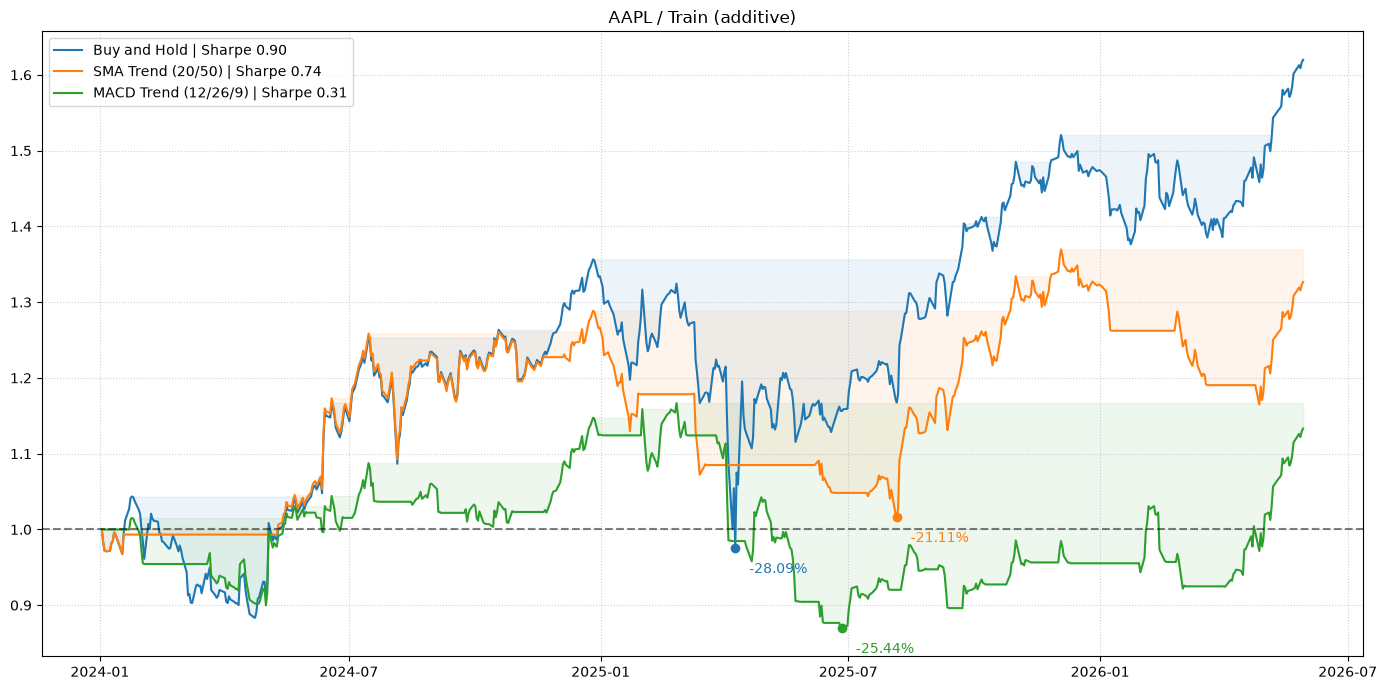

/var/folders/1n/4m_zt2yn3jq9xkrxx1894sdc0000gp/T/ipykernel_19824/520095210.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  metrics = metrics_table.loc[(ticker, period)]


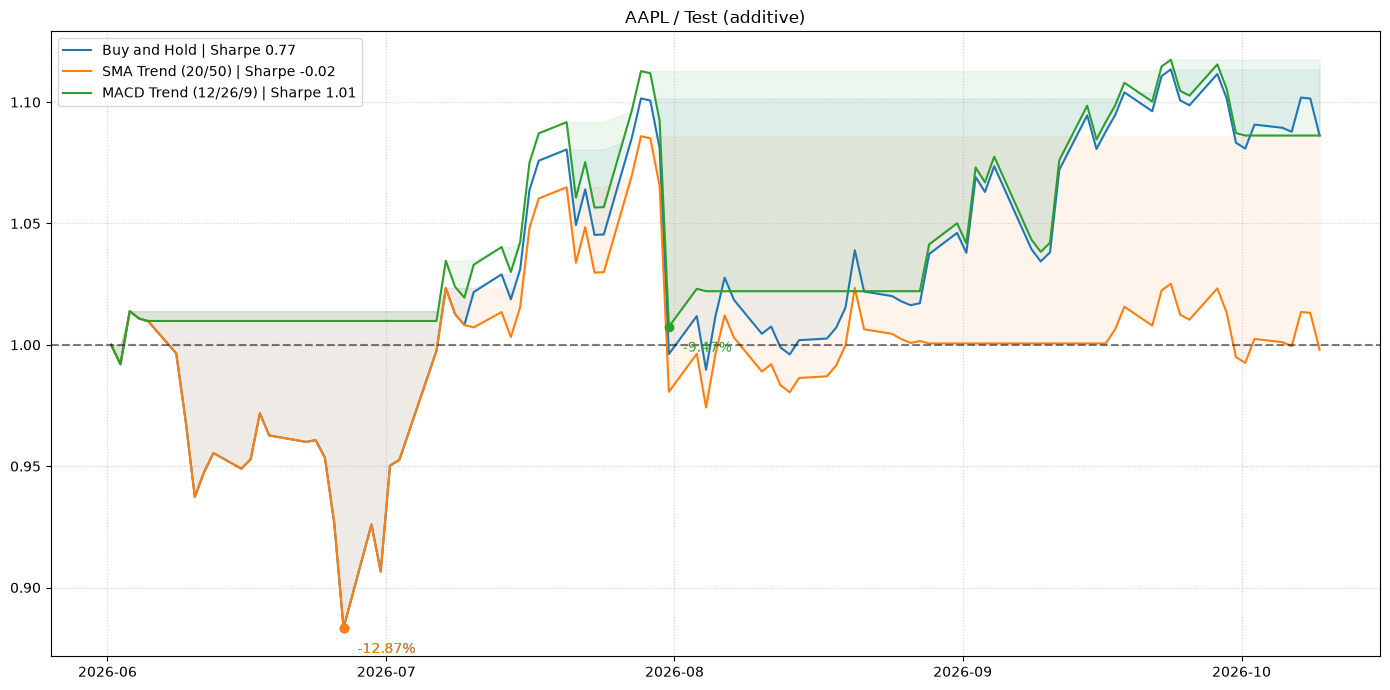

/var/folders/1n/4m_zt2yn3jq9xkrxx1894sdc0000gp/T/ipykernel_19824/520095210.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  metrics = metrics_table.loc[(ticker, period)]


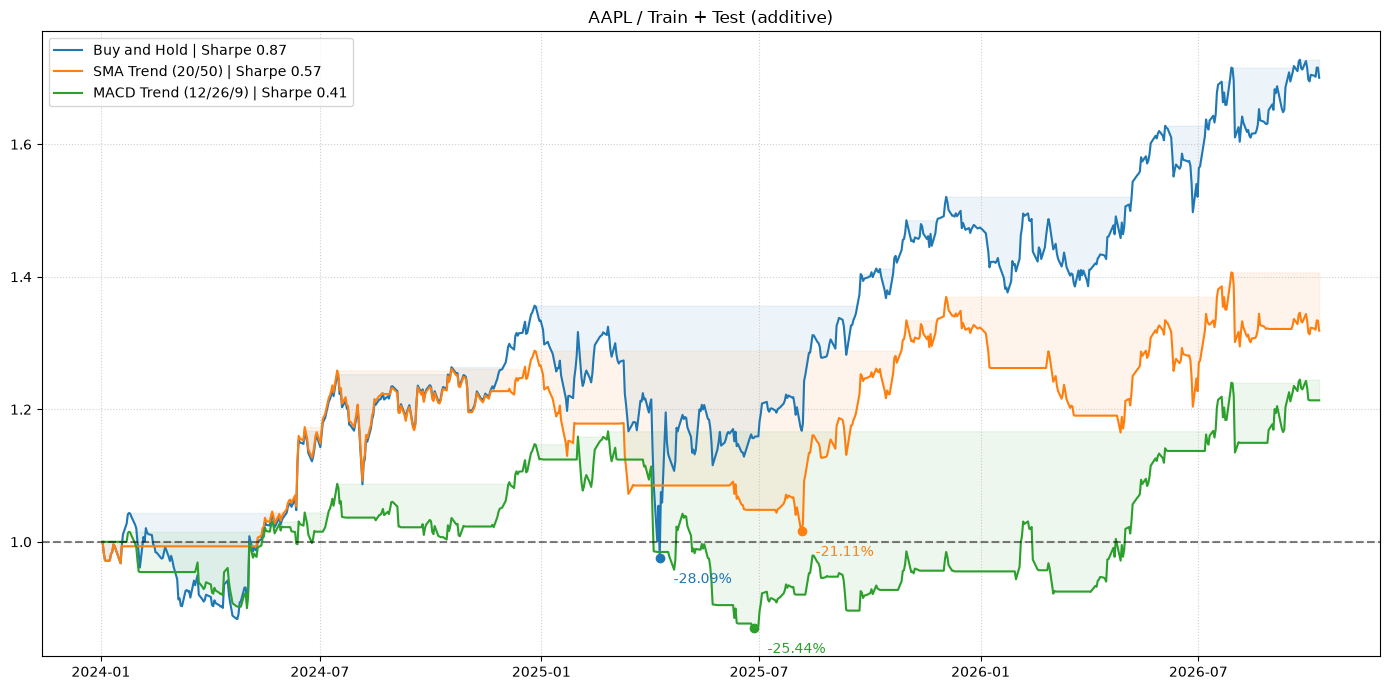

/var/folders/1n/4m_zt2yn3jq9xkrxx1894sdc0000gp/T/ipykernel_19824/520095210.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  metrics = metrics_table.loc[(ticker, period)]


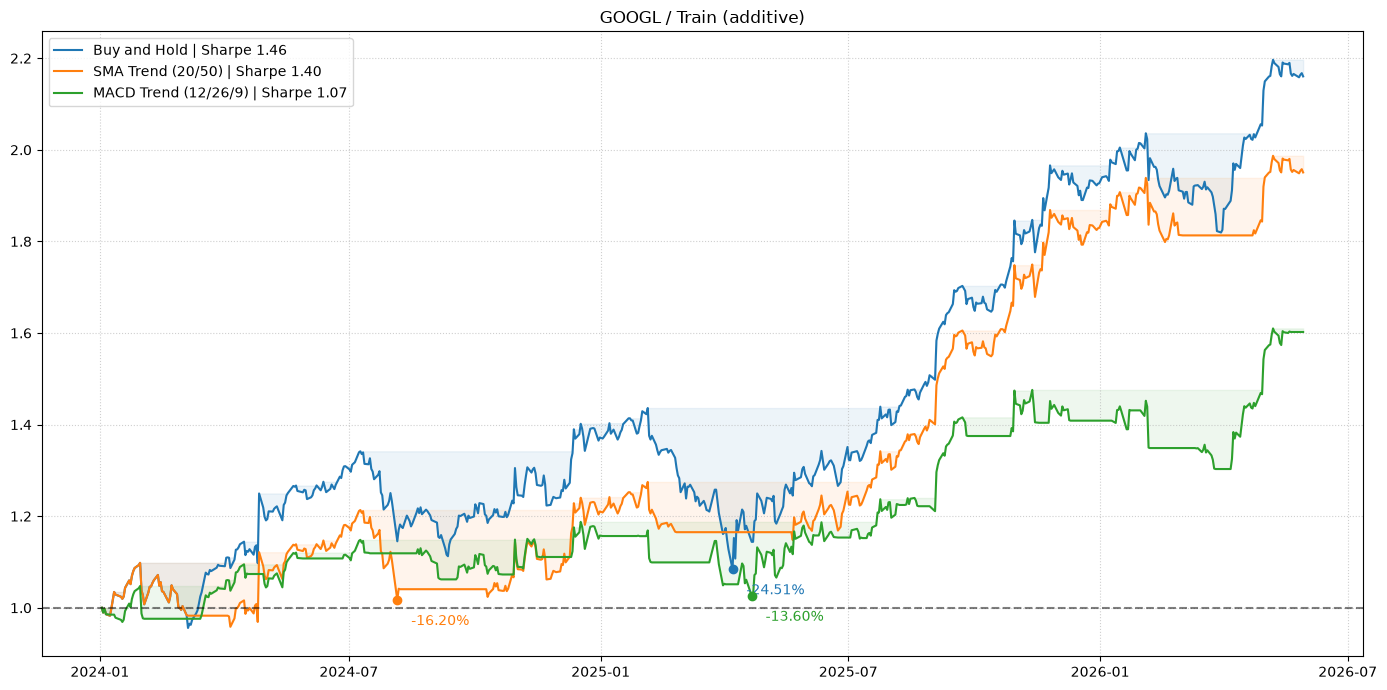

/var/folders/1n/4m_zt2yn3jq9xkrxx1894sdc0000gp/T/ipykernel_19824/520095210.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  metrics = metrics_table.loc[(ticker, period)]


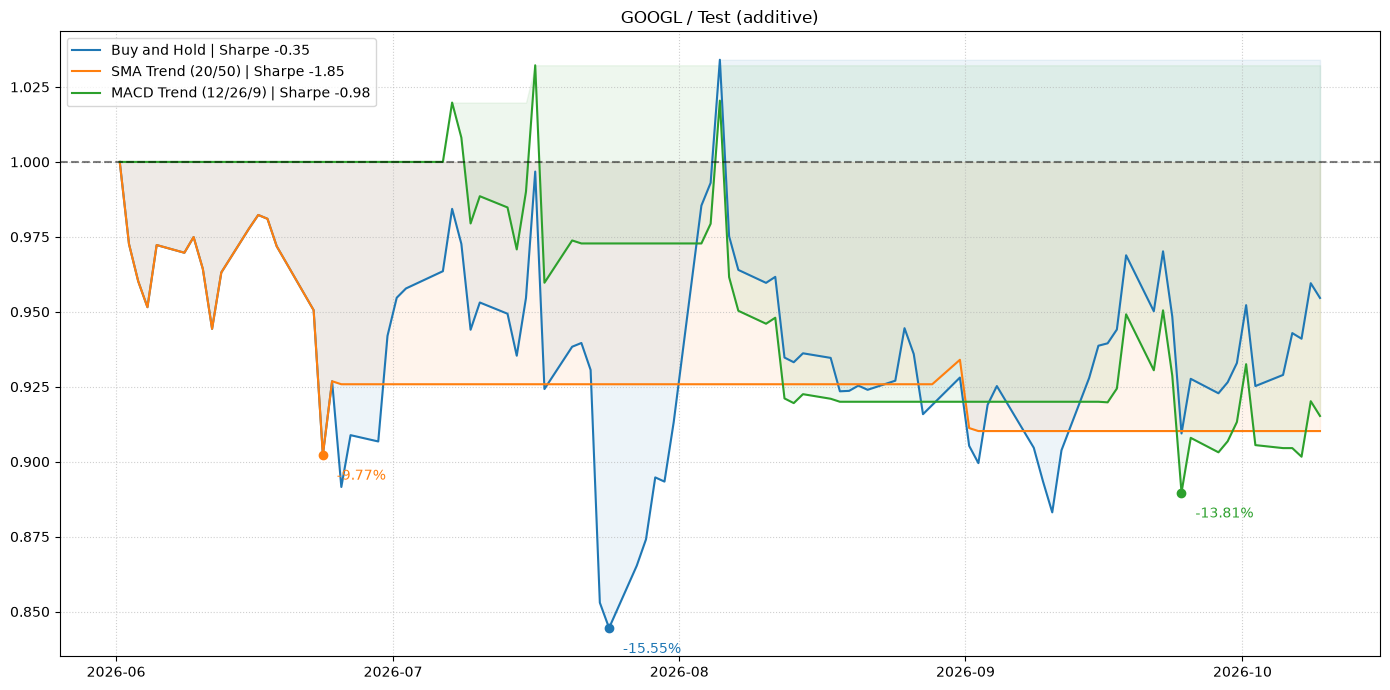

/var/folders/1n/4m_zt2yn3jq9xkrxx1894sdc0000gp/T/ipykernel_19824/520095210.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  metrics = metrics_table.loc[(ticker, period)]


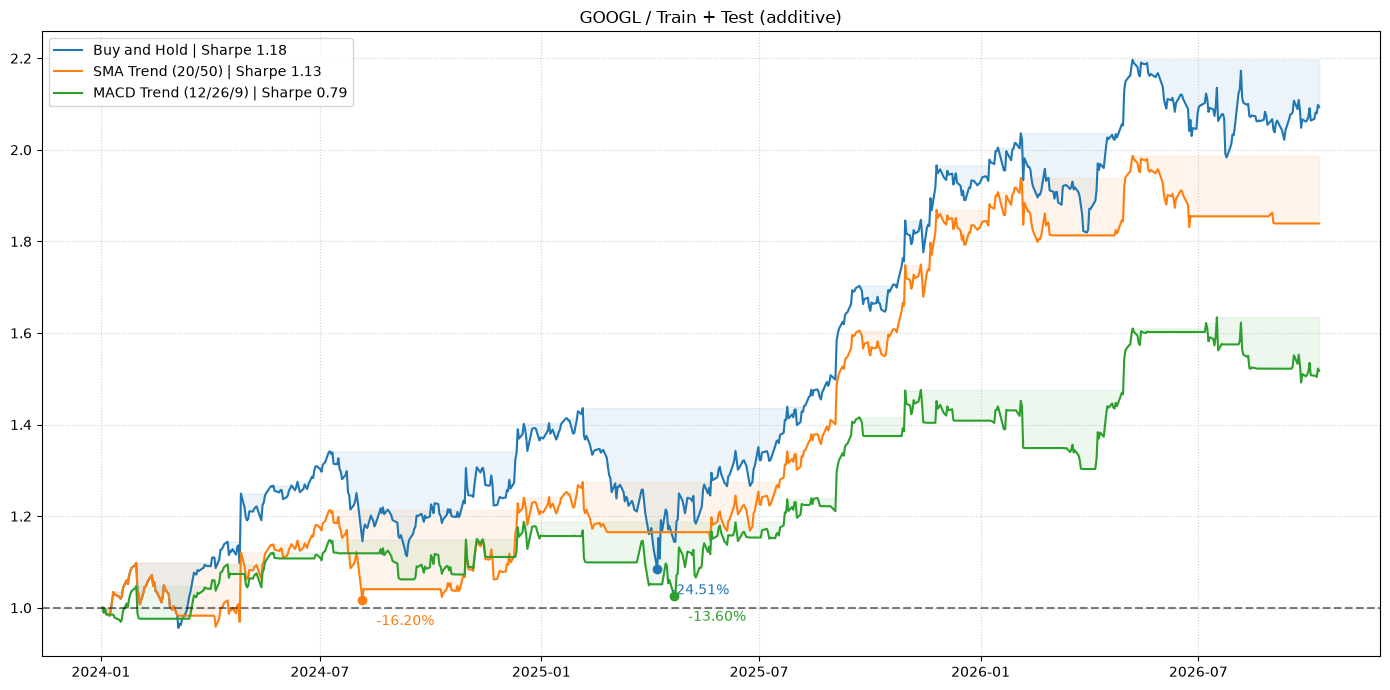

/var/folders/1n/4m_zt2yn3jq9xkrxx1894sdc0000gp/T/ipykernel_19824/520095210.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  metrics = metrics_table.loc[(ticker, period)]


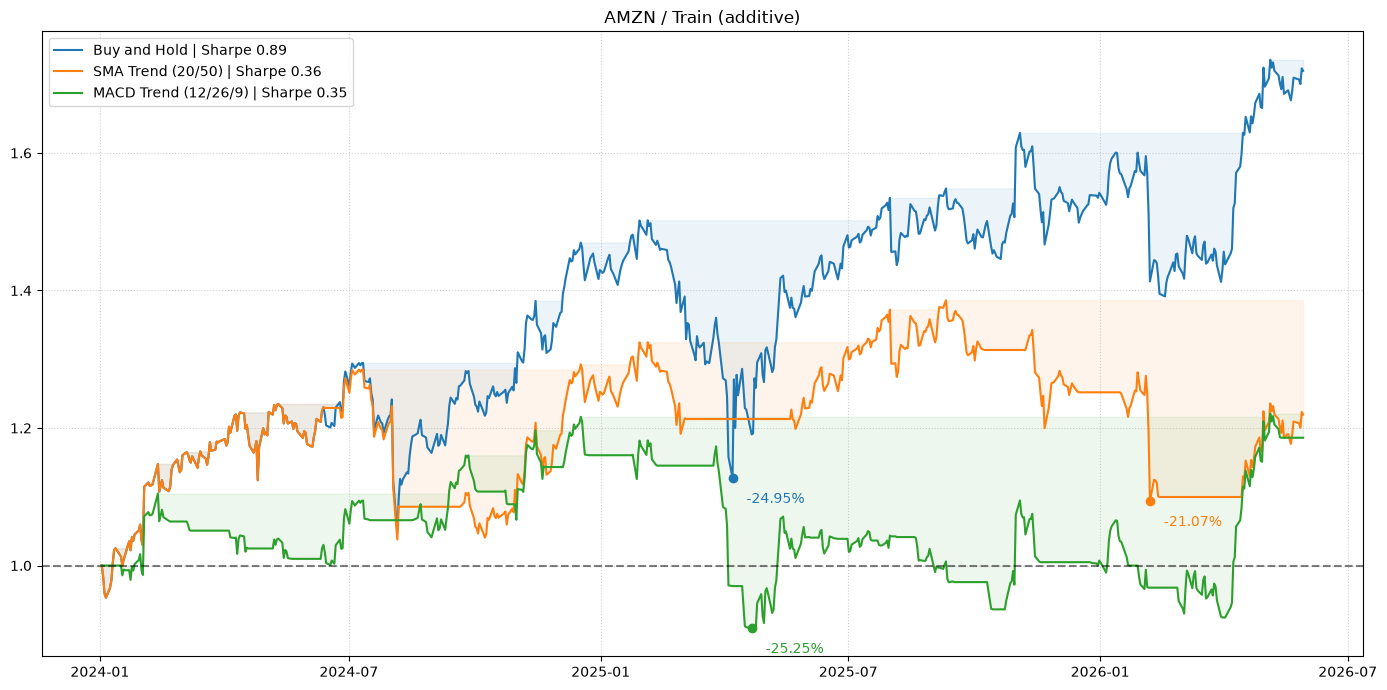

/var/folders/1n/4m_zt2yn3jq9xkrxx1894sdc0000gp/T/ipykernel_19824/520095210.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  metrics = metrics_table.loc[(ticker, period)]


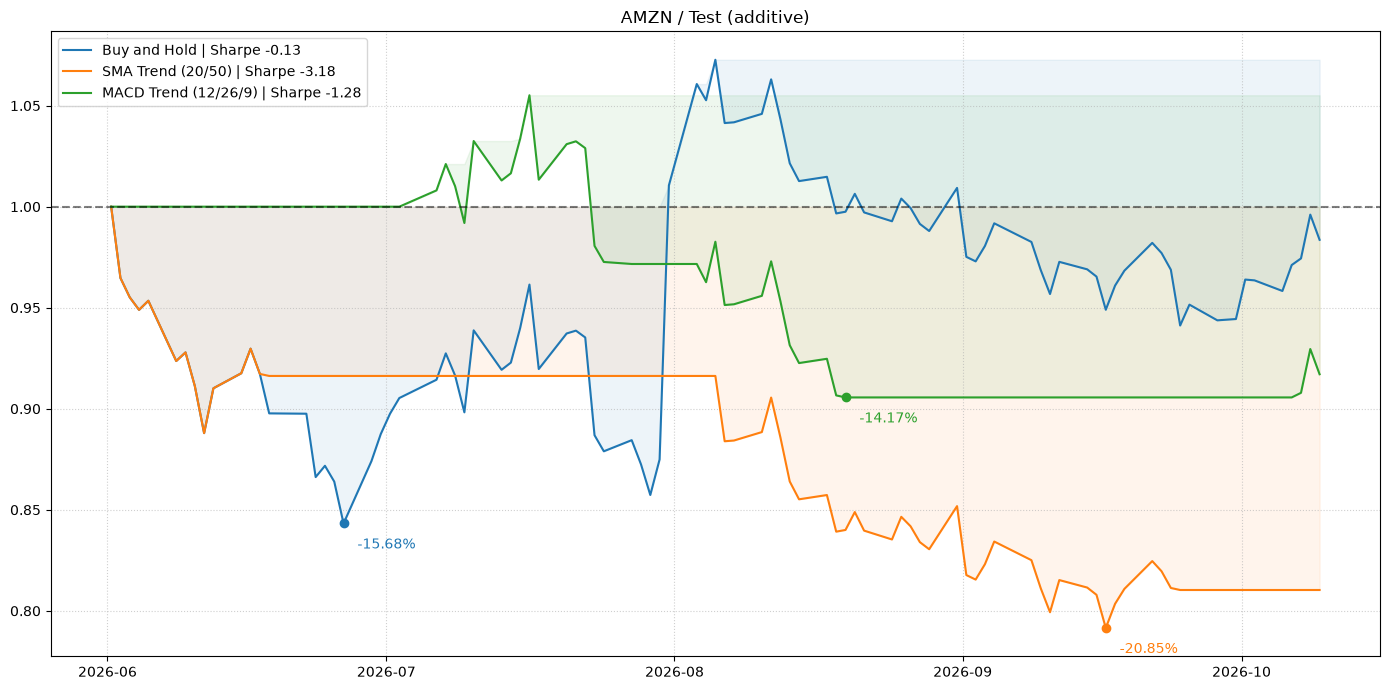

/var/folders/1n/4m_zt2yn3jq9xkrxx1894sdc0000gp/T/ipykernel_19824/520095210.py:6: PerformanceWarning: indexing past lexsort depth may impact performance.
  metrics = metrics_table.loc[(ticker, period)]


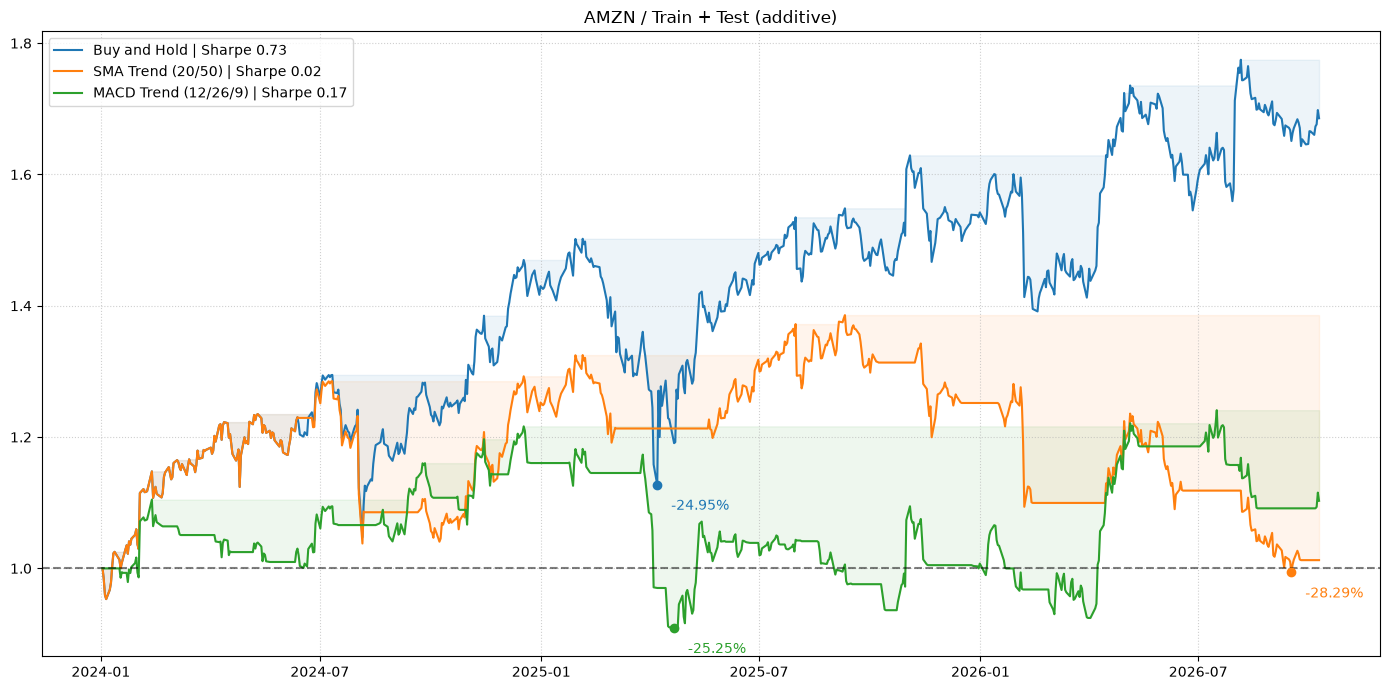

In [22]:
figures = {}
for ticker in TICKERS:
    for period in periods:
        frames = {strategy: frame for (stock, scope, strategy), frame in backtests.items()
                  if stock == ticker and scope == period}
        metrics = metrics_table.loc[(ticker, period)]
        fig, curves = plot_backtest(frames, strategy_names, metrics,
                                   f"{ticker} / {period_names[period]}", nav_mode=NAV_MODE)
        figures[ticker, period] = fig
        plt.show()
        plt.close(fig)

## 月收益与结果导出
月收益按对应净值口径聚合。results/metrics.csv 汇总全部股票、范围和策略，详细结果按 股票／范围／策略 保存；每只股票的三个范围分别导出图片。
原始行情与真实 Agent 输入不会被清理。

In [23]:
monthly_tables = {}
for key, frame in backtests.items():
    interval_ret = pd.Series(frame.strategy_ret.to_numpy(), index=pd.DatetimeIndex(frame.return_end))
    monthly_tables[key] = ((1 + interval_ret).resample("ME").prod() - 1
                           if NAV_MODE == "compound" else interval_ret.resample("ME").sum())
monthly_returns = pd.concat(monthly_tables, names=["ticker", "period", "strategy", "month"]).rename("return")
monthly_returns.to_frame()

return
ticker period     strategy month                              
AAPL   train      buy_hold 2024-01-31 00:00:00-05:00 -0.000011
                           2024-02-29 00:00:00-05:00 -0.027946
                           2024-03-31 00:00:00-04:00 -0.051928
                           2024-04-30 00:00:00-04:00  0.010724
                           2024-05-31 00:00:00-04:00  0.105191
...                                                        ...
AMZN   train_test macd     2026-06-30 00:00:00-04:00  0.000000
                           2026-07-31 00:00:00-04:00 -0.028355
                           2026-08-31 00:00:00-04:00 -0.066032
                           2026-09-30 00:00:00-04:00  0.000000
                           2026-10-31 00:00:00-04:00  0.011475

[612 rows x 1 columns]

In [24]:
import shutil
output_dir = ROOT / "results"
output_dir.mkdir(exist_ok=True)
# 仅更新本项目生成的结果，清理旧目录结构和旧图片。
for name in cfg["tickers"] + ["development", "validation", "test"]:
    folder = output_dir / name
    if folder.exists():
        shutil.rmtree(folder)
for path in output_dir.glob("*.png"):
    path.unlink()
(output_dir / "run.json").unlink(missing_ok=True)
metrics_table.to_csv(output_dir / "metrics.csv")
monthly_returns.to_csv(output_dir / "monthly_returns.csv")
for (ticker, period, strategy), frame in backtests.items():
    folder = output_dir / ticker / period / strategy
    folder.mkdir(parents=True, exist_ok=True)
    frame.to_csv(folder / "daily.csv")
    frame.loc[frame.turnover > 0, ["signal_session", "date", "open", "position_changes", "position", "cost"]].to_csv(folder / "position_changes.csv")
for (ticker, strategy), decisions in decision_tables.items():
    decisions.to_csv(output_dir / ticker / f"{strategy}_decisions.csv", index=False)
for (ticker, period), figure in figures.items():
    figure.savefig(output_dir / ticker / f"{period}_equity_drawdown.png", dpi=120, bbox_inches="tight")
record = {
    "created_at": utcnow(), "status": "complete", "tickers": TICKERS,
    "strategies": strategy_names, "periods": periods, "return_type": RETURN_TYPE,
    "nav_mode": NAV_MODE, "fee": fee, "config": cfg, "data_hash": data_hash(),
    "code_hash": code_hash(), "python": sys.executable,
    "agent_status": "待接入" if AGENT_CSV is None else "外部最终经理 CSV",
    "agent_csv_sha256": None if AGENT_CSV is None else digest(Path(AGENT_CSV).read_bytes()),
    "files": {str(p.relative_to(output_dir)): digest(p.read_bytes())
              for p in output_dir.rglob("*") if p.is_file()},
}
(output_dir / "run.json").write_bytes(json_bytes(record))
str(output_dir)

'/Users/Admin/Documents/hkust/course/BDT5018NLP/Group Project/TradingAgents/tradingagents_quant_backtest/results'